In [1]:
# ============================================================
# E-Commerce 360° Business Intelligence
# ============================================================
#
# STEP 03 — EXPLORATORY DATA ANALYSIS (EDA)
#
# Business objective:
# Discover sales, product, customer, payment, review and delivery
# patterns in the Olist marketplace data.
#
# We will create business-focused charts and summarize
# the main findings.
#
# Important metric definition:
# Product revenue = sum of item price.
# Freight is analyzed separately.
# Freight is NOT included in product revenue.
#
# ============================================================

In [2]:
# Cell 1 — Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

print("EDA started successfully!")

EDA started successfully!


In [3]:
# Cell 2 — Load cleaned datasets
# Load cleaned datasets

orders = pd.read_csv("processed/orders_clean.csv")
items = pd.read_csv("processed/order_items_clean.csv")
customers = pd.read_csv("processed/customers_clean.csv")
products = pd.read_csv("processed/products_clean.csv")
payments = pd.read_csv("processed/payments_clean.csv")
reviews = pd.read_csv("processed/reviews_clean.csv")

# Convert dates

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"]
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"]
)

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [4]:
#  Cell 3 — Create master analysis dataset

# Merge orders and order items

df = items.merge(
    orders,
    on="order_id",
    how="left"
)

# Merge customer information

df = df.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Merge product information

df = df.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Calculate product revenue

df["revenue"] = df["price"]

# Create month column

df["month"] = df["order_purchase_timestamp"].dt.to_period("M")

print("Master dataset created:", df.shape)

display(df.head())

Master dataset created: (112650, 18)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state,product_category_name,revenue,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,RJ,cool_stuff,58.90,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,SP,pet_shop,239.90,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,MG,moveis_decoracao,199.00,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,SP,perfumaria,12.99,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,SP,ferramentas_jardim,199.90,2017-02


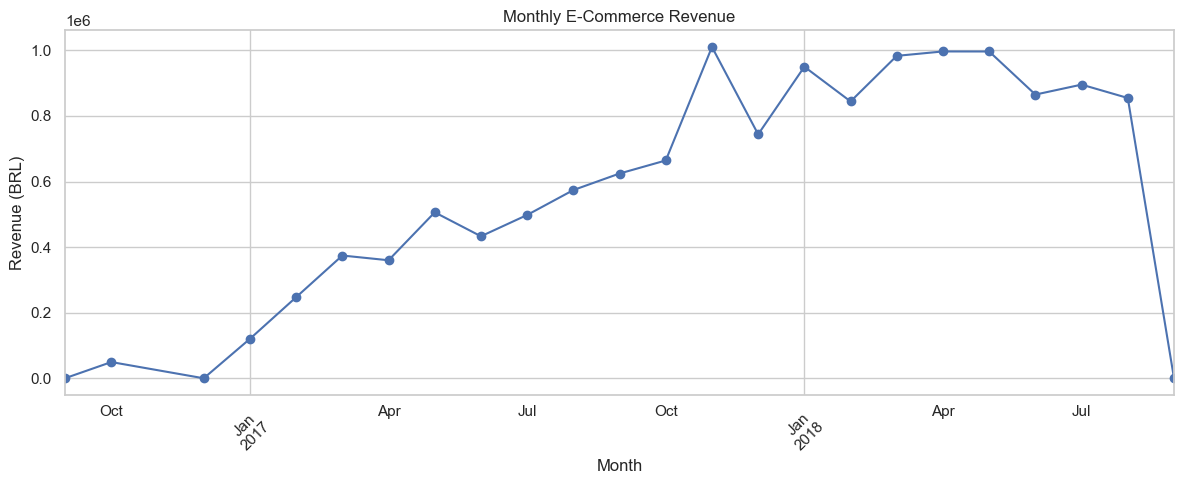

In [5]:
# Cell 4 — Monthly revenue analysis
monthly_sales = df.groupby("month")["revenue"].sum()

monthly_sales.plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly E-Commerce Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

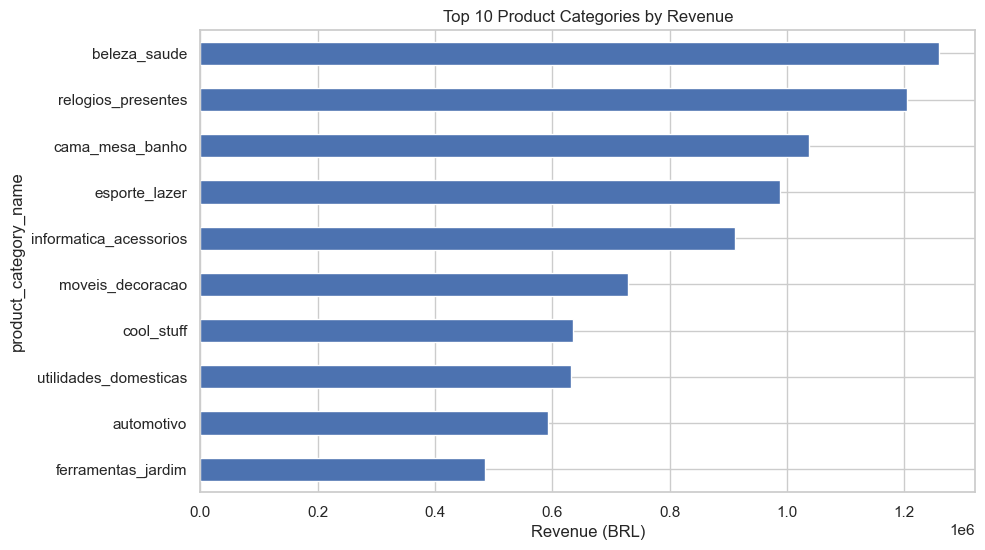

In [6]:
# Cell 5 — Top 10 product categories
top_products = (
    df.groupby("product_category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Categories by Revenue"
)

plt.xlabel("Revenue (BRL)")
plt.show()

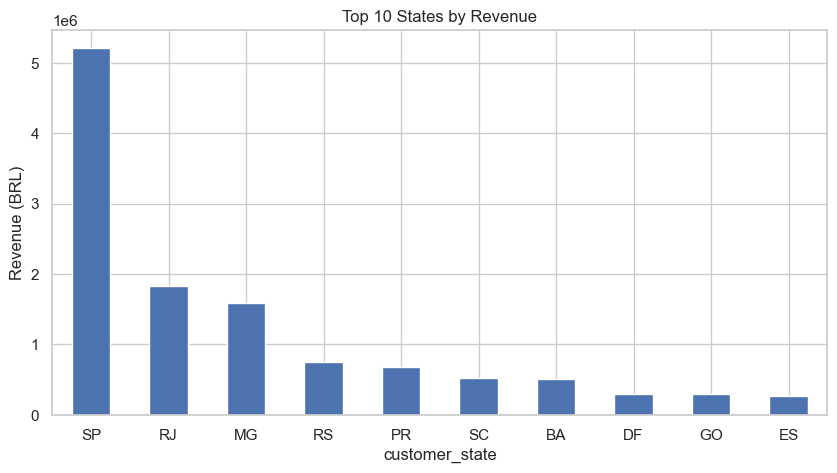

In [7]:
# Cell 6 — State-wise sales
state_sales = (
    df.groupby("customer_state")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

state_sales.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 States by Revenue"
)

plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=0)
plt.show()

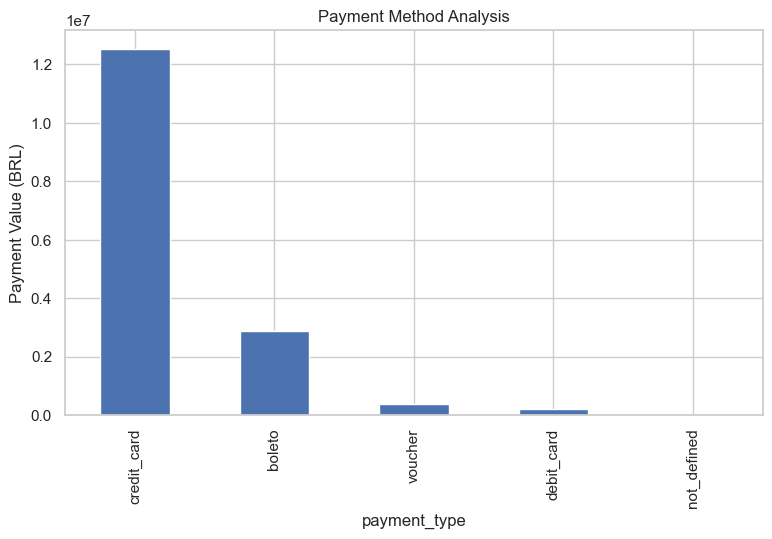

In [8]:
# Cell 7 — Payment analysis
payment_analysis = payments.groupby(
    "payment_type"
)["payment_value"].sum().sort_values(ascending=False)

payment_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    title="Payment Method Analysis"
)

plt.ylabel("Payment Value (BRL)")
plt.show()

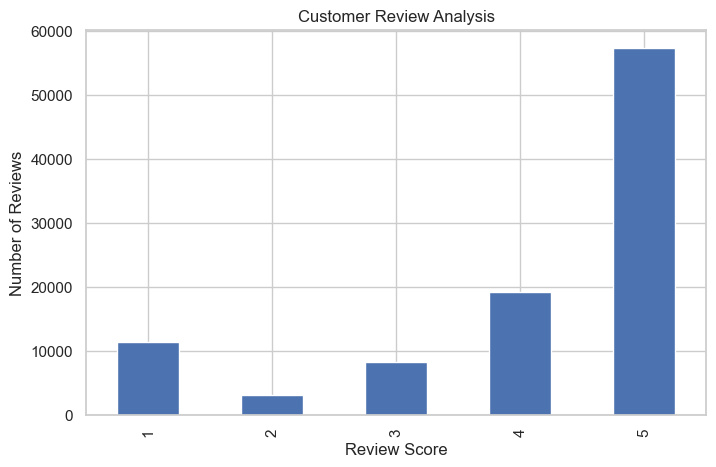

In [9]:
# Cell 8 — Customer review analysis
review_analysis = reviews["review_score"].value_counts().sort_index()

review_analysis.plot(
    kind="bar",
    figsize=(8, 5),
    title="Customer Review Analysis"
)

plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.show()

Average delivery days: 12.56


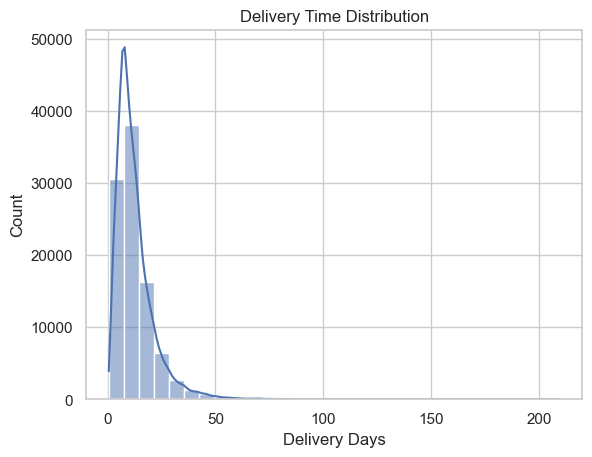

In [10]:
# Cell 9 — Delivery performance
delivered = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
].copy()

delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print("Average delivery days:",
      round(delivered["delivery_days"].mean(), 2))

sns.histplot(
    delivered["delivery_days"].dropna(),
    bins=30,
    kde=True
)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Days")
plt.show()

In [11]:
# Cell 10 — Business KPI summary
total_orders = orders["order_id"].nunique()

delivered_orders = orders[
    orders["order_status"] == "delivered"
]["order_id"].nunique()

total_revenue = df["revenue"].sum()

average_order_value = (
    df.groupby("order_id")["revenue"].sum().mean()
)

print("=" * 45)
print("E-COMMERCE BUSINESS KPI REPORT")
print("=" * 45)

print("Total Orders:", total_orders)
print("Delivered Orders:", delivered_orders)
print("Product Revenue:", round(total_revenue, 2))
print("Average Product Value per Order:", round(average_order_value, 2))

print("=" * 45)
print("EDA COMPLETED SUCCESSFULLY!")

E-COMMERCE BUSINESS KPI REPORT
Total Orders: 99441
Delivered Orders: 96478
Product Revenue: 13591643.7
Average Product Value per Order: 137.75
EDA COMPLETED SUCCESSFULLY!
